# SMAP-enhanced surface soil moisture: March–August 2020

NASA/JPL Mongolia research, scientifically reconstructed from six real archived NASA–USDA enhanced SMAP monthly ssma rasters. This is an observation-assimilating drought model product, **not raw SMAP radiometer measurements**.

In [1]:
from pathlib import Path
import sys
PROJECT = Path.cwd()
if not (PROJECT / 'src').exists():
    PROJECT = PROJECT.parent
assert (PROJECT / 'src').exists(), 'Run notebook from repository root or notebooks/'
sys.path.insert(0, str(PROJECT))
from IPython.display import display, Image
import pandas as pd


## Fixes relative to 2022 draft
The original code combined June–August data but titled the result June; then it used a **mode** in time and **sum** over each province while labelling the result a mean. This rebuild uses one archived monthly raster per calendar month, valid-cell spatial **means** weighted approximately by geographic pixel area.

In [2]:
from src.pipeline import compute_smap, check_smap_common_zero_mask, RESULTS
monthly, zero_cells = compute_smap()
print('Monthly provincial records:', len(monthly))
print('Identical zero-filled cells across all six archived rasters:',zero_cells)
display(monthly.groupby('month').ssma_mean.agg(['min','mean','max']).reindex(['March','April','May','June','July','August']).round(4))

Monthly provincial records: 132
Identical zero-filled cells across all six archived rasters: 2234492


,min,mean,max
month,,,
March,-0.5328,-0.0992,0.3218
April,-1.1463,-0.6006,-0.1585
May,-1.0925,-0.2924,0.5943
June,-0.5595,-0.0183,0.6473
July,-0.2733,0.1708,0.5500
August,-0.4729,0.4717,1.0352


## Actual March–August drought-condition maps
The same zero locations occur in all six raster files and are treated as exported missing-data pixels, not real zero anomalies. Southern/western province coverage is uneven; see the printed coverage percentages.

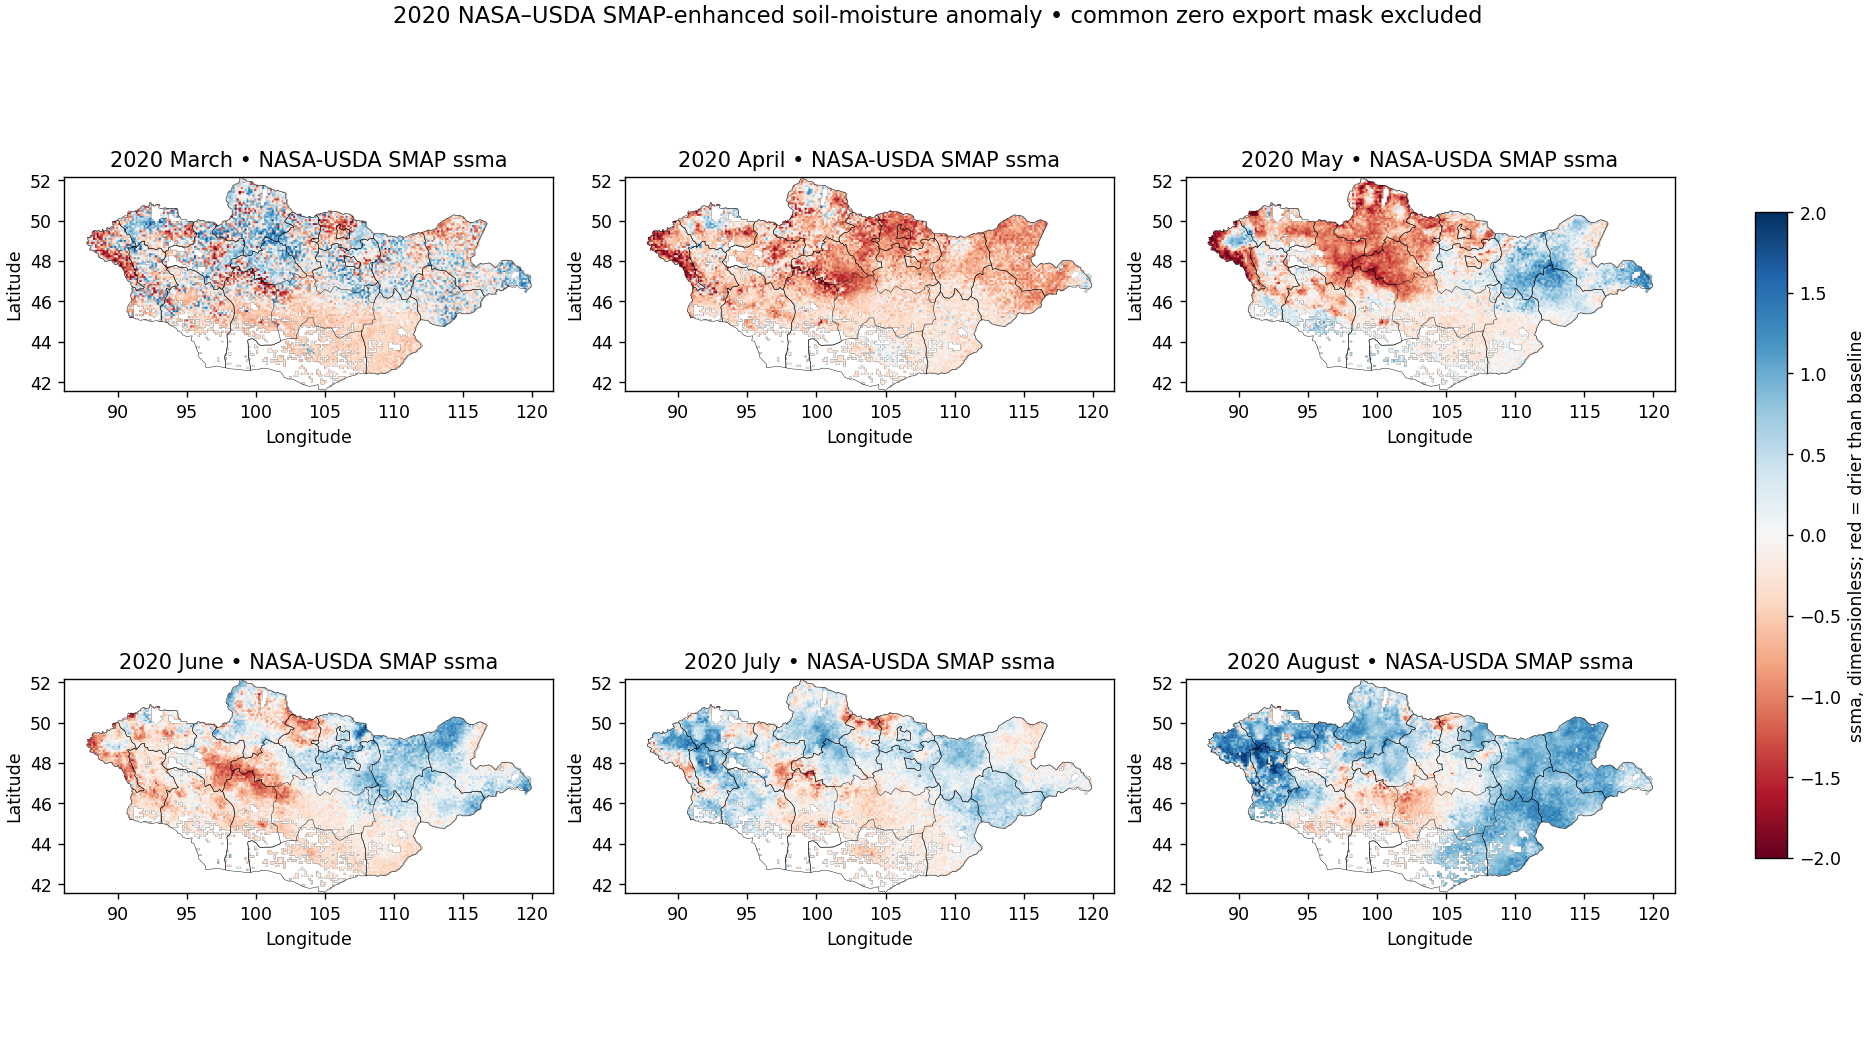

,Minimum usable pixel coverage (%)
province,
Umnugovi,46.8
Bayankhongor,65.3
GoviAltai,68.3
uvs,87.6
Khovd,89.0
Zavkhan,89.1
Dornogovi,93.0


In [3]:
display(Image(filename=str(RESULTS/'03_smap_2020_march_august.png'),width=1080))
display(monthly.groupby('province').valid_fraction.min().sort_values().head(7).mul(100).round(1).rename('Minimum usable pixel coverage (%)').to_frame())

## Research boundary
These files contain only the **archived monthly composites**. Raw scene-level QA, original daily observations and their complete anomaly baseline are not present here, so this notebook does not claim to validate the satellite assimilation algorithm or annual drought attribution.